In [561]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [562]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

In [563]:
df = pd.read_csv('car_price_prediction.csv')

In [564]:
df

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19232,45798355,8467,-,MERCEDES-BENZ,CLK 200,1999,Coupe,Yes,CNG,2.0 Turbo,300000 km,4.0,Manual,Rear,02-Mar,Left wheel,Silver,5
19233,45778856,15681,831,HYUNDAI,Sonata,2011,Sedan,Yes,Petrol,2.4,161600 km,4.0,Tiptronic,Front,04-May,Left wheel,Red,8
19234,45804997,26108,836,HYUNDAI,Tucson,2010,Jeep,Yes,Diesel,2,116365 km,4.0,Automatic,Front,04-May,Left wheel,Grey,4
19235,45793526,5331,1288,CHEVROLET,Captiva,2007,Jeep,Yes,Diesel,2,51258 km,4.0,Automatic,Front,04-May,Left wheel,Black,4


In [565]:
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


### 1 первичное статистическое исследование количественных и категориальных признаков

In [566]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  object 
 3   Manufacturer      19237 non-null  object 
 4   Model             19237 non-null  object 
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  object 
 7   Leather interior  19237 non-null  object 
 8   Fuel type         19237 non-null  object 
 9   Engine volume     19237 non-null  object 
 10  Mileage           19237 non-null  object 
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  object 
 13  Drive wheels      19237 non-null  object 
 14  Doors             19237 non-null  object 
 15  Wheel             19237 non-null  object 
 16  Color             19237 non-null  object

In [567]:
df.describe()

,ID,Price,Prod. year,Cylinders,Airbags
count,1.923700e+04,1.923700e+04,19237.000000,19237.000000,19237.000000
mean,4.557654e+07,1.855593e+04,2010.912824,4.582991,6.582627
std,9.365914e+05,1.905813e+05,5.668673,1.199933,4.320168
min,2.074688e+07,1.000000e+00,1939.000000,1.000000,0.000000
25%,4.569837e+07,5.331000e+03,2009.000000,4.000000,4.000000
50%,4.577231e+07,1.317200e+04,2012.000000,4.000000,6.000000
75%,4.580204e+07,2.207500e+04,2015.000000,4.000000,12.000000
max,4.581665e+07,2.630750e+07,2020.000000,16.000000,16.000000


In [568]:
df.describe(include=['O'])

,Levy,Manufacturer,Model,Category,Leather interior,Fuel type,Engine volume,Mileage,Gear box type,Drive wheels,Doors,Wheel,Color
count,19237,19237,19237,19237,19237,19237,19237,19237,19237,19237,19237,19237,19237
unique,559,65,1590,11,2,7,107,7687,4,3,3,2,16
top,-,HYUNDAI,Prius,Sedan,Yes,Petrol,2,0 km,Automatic,Front,04-May,Left wheel,Black
freq,5819,3769,1083,8736,13954,10150,3916,721,13514,12874,18332,17753,5033


In [569]:
df['Gear box type'].value_counts()

Gear box type
Automatic    13514
Tiptronic     3102
Manual        1875
Variator       746
Name: count, dtype: int64

In [570]:
df['Drive wheels'].value_counts()

Drive wheels
Front    12874
4x4       4058
Rear      2305
Name: count, dtype: int64

In [571]:
df['Fuel type'].value_counts()

Fuel type
Petrol            10150
Diesel             4036
Hybrid             3578
LPG                 892
CNG                 494
Plug-in Hybrid       86
Hydrogen              1
Name: count, dtype: int64

In [572]:
df['Color'].value_counts()

Color
Black            5033
White            4489
Silver           3792
Grey             2375
Blue             1396
Red               639
Green             322
Orange            253
Brown             187
Carnelian red     179
Golden            145
Beige             134
Sky blue          122
Yellow            106
Purple             39
Pink               26
Name: count, dtype: int64

In [573]:
df['Category'].value_counts()

Category
Sedan          8736
Jeep           5473
Hatchback      2847
Minivan         647
Coupe           532
Universal       364
Microbus        306
Goods wagon     233
Pickup           52
Cabriolet        36
Limousine        11
Name: count, dtype: int64

In [574]:
df['Prod. year'].value_counts()

Prod. year
2012    2155
2014    2124
2013    1963
2011    1612
2015    1549
2010    1483
2016    1476
2017     959
2008     737
2009     601
2018     500
2007     464
2005     402
2003     367
2004     364
2006     317
2019     306
2002     296
2000     279
2001     254
1998     213
1999     207
1997     151
1996     114
1995     105
2020      47
1994      42
1992      30
1993      23
1990      18
1988      12
1991      10
1986       6
1989       6
1987       5
1984       5
1985       5
1953       4
1983       3
1939       3
1978       2
1980       2
1965       2
1977       2
1974       2
1964       2
1943       1
1976       1
1957       1
1968       1
1947       1
1982       1
1981       1
1973       1
Name: count, dtype: int64

In [575]:
df.drop("ID", axis=1, inplace=True)

In [576]:
numeric_columns = ['Price', 'Prod. year', 'Cylinders', 'Airbags']
categorical_columns = ['Manufacturer', 'Model', 'Category', 'Leather interior',
                      'Fuel type', 'Gear box type' , 'Drive wheels', 'Doors',
                      'Wheel', 'Color']


### 2 наличие пропусков 

In [577]:
print("Анализ пропущенных значений:")
missing_data = df.isnull().sum()
print(missing_data)
print("\n" + "="*50 + "\n")

Анализ пропущенных значений:
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64




### 3 визуализация распределения значений.

In [578]:
df['Mileage'] = df['Mileage'].str.replace(' km', '').astype(int)
numeric_columns.append('Mileage')

Очищен от текстовых значений 'km' и преобразован в целочисленный тип.

In [579]:
def split_engine_volume(volume_str):
    if isinstance(volume_str, str):
        is_turbo = 'Turbo' in volume_str
        volume_str = volume_str.replace(' Turbo', '').strip()
        try:
            volume = float(volume_str)
        except ValueError:
            volume = np.nan
        return pd.Series([volume, is_turbo])
    return pd.Series([volume_str, False])

In [580]:
df[['Engine volume', 'Is Turbo']] = df['Engine volume'].apply(split_engine_volume)

categorical_columns.append('Is Turbo')
numeric_columns.append('Engine volume')

Очищен от Turbo и преобразован в числовой тип

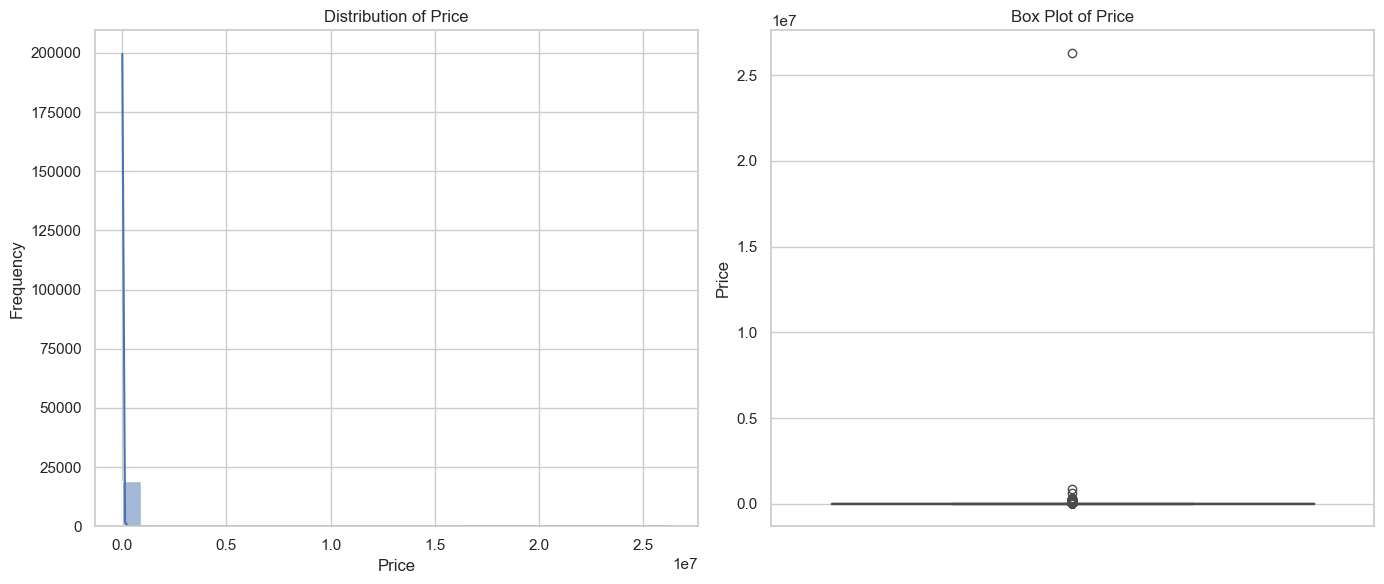

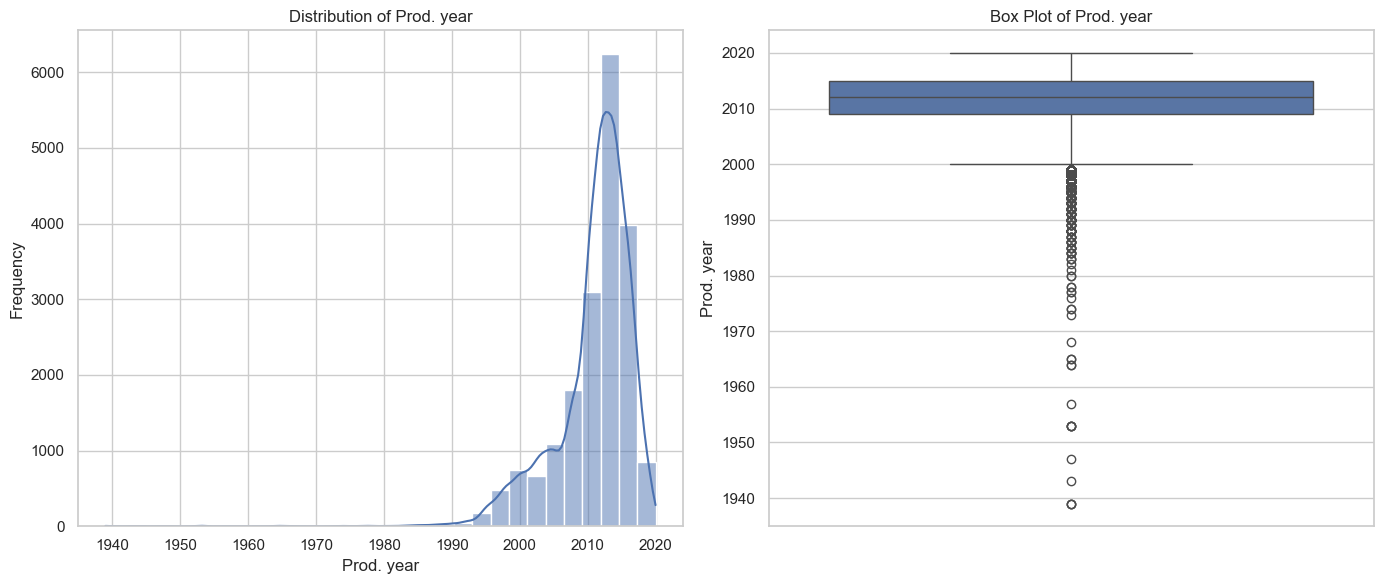

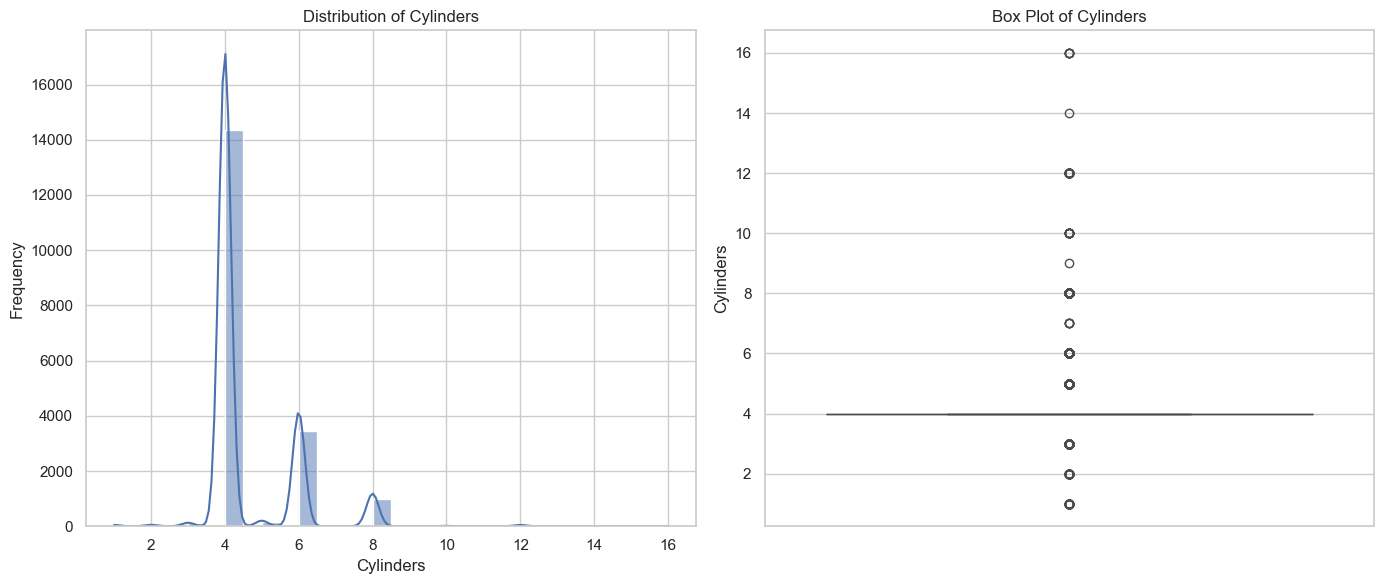

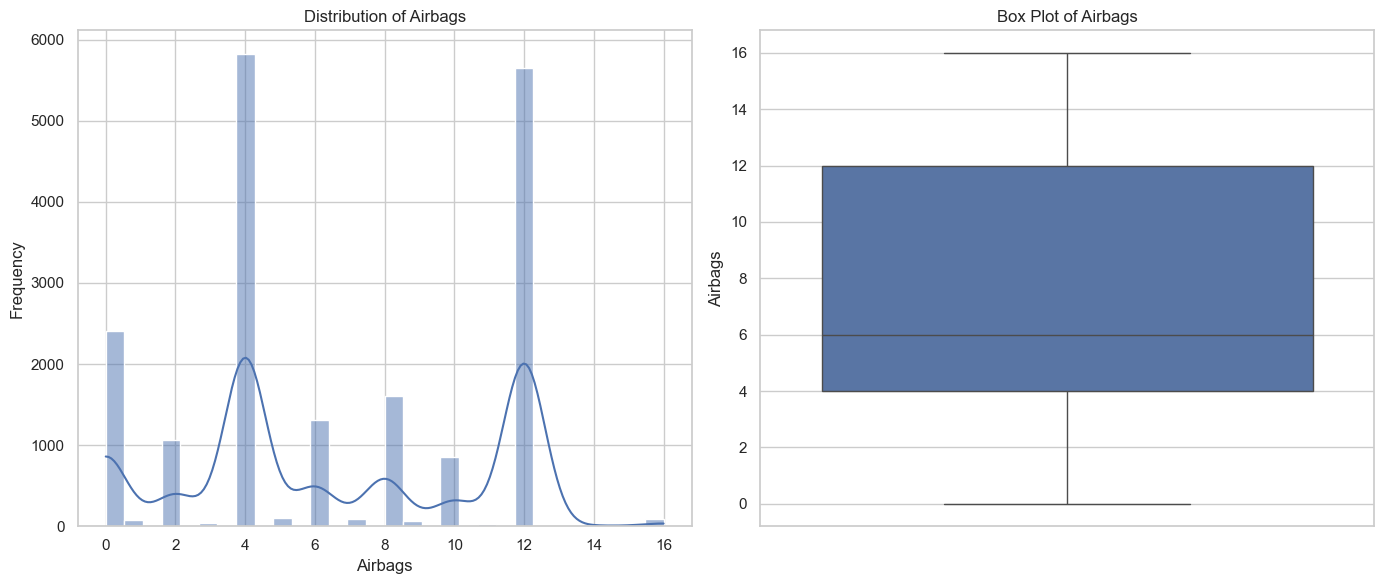

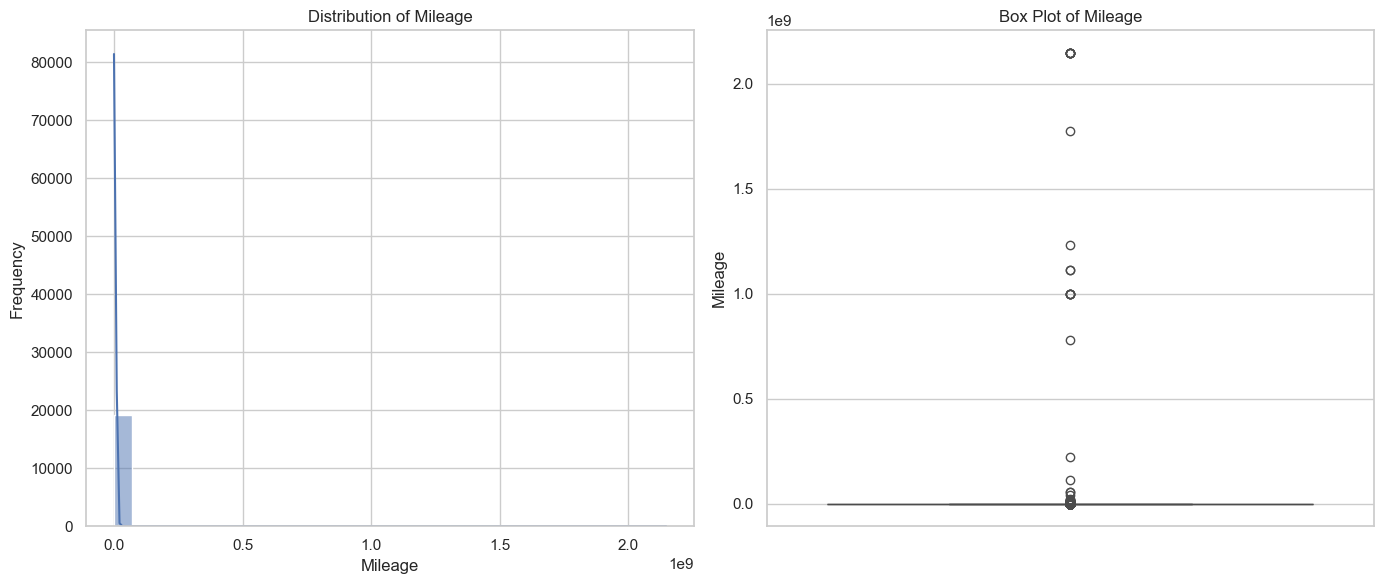

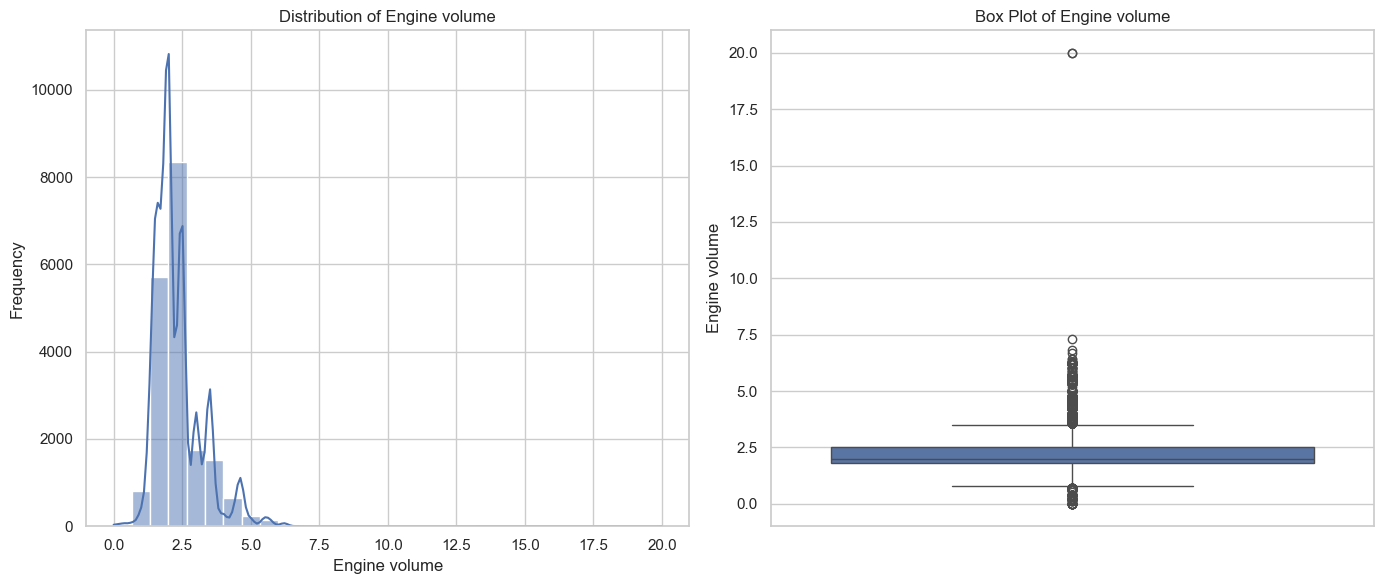

In [581]:
for feature in numeric_columns:
    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    sns.histplot(df[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

    plt.subplot(1, 2, 2)
    sns.boxplot(y=df[feature].dropna())
    plt.title(f'Box Plot of {feature}')
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

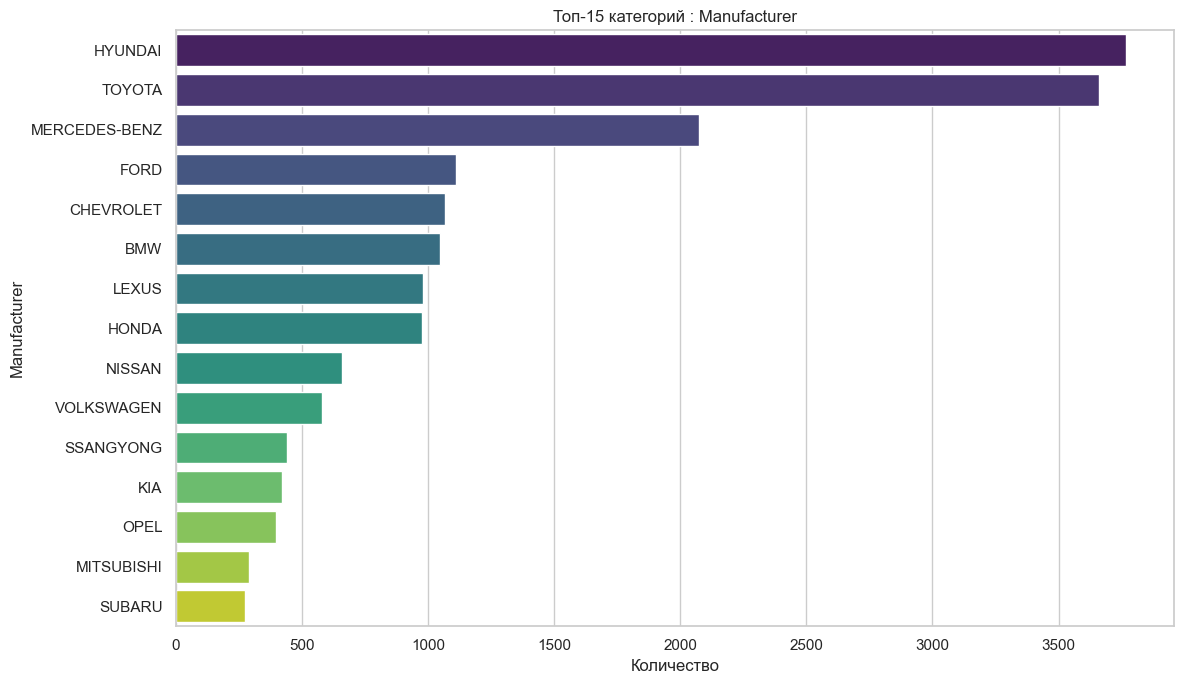

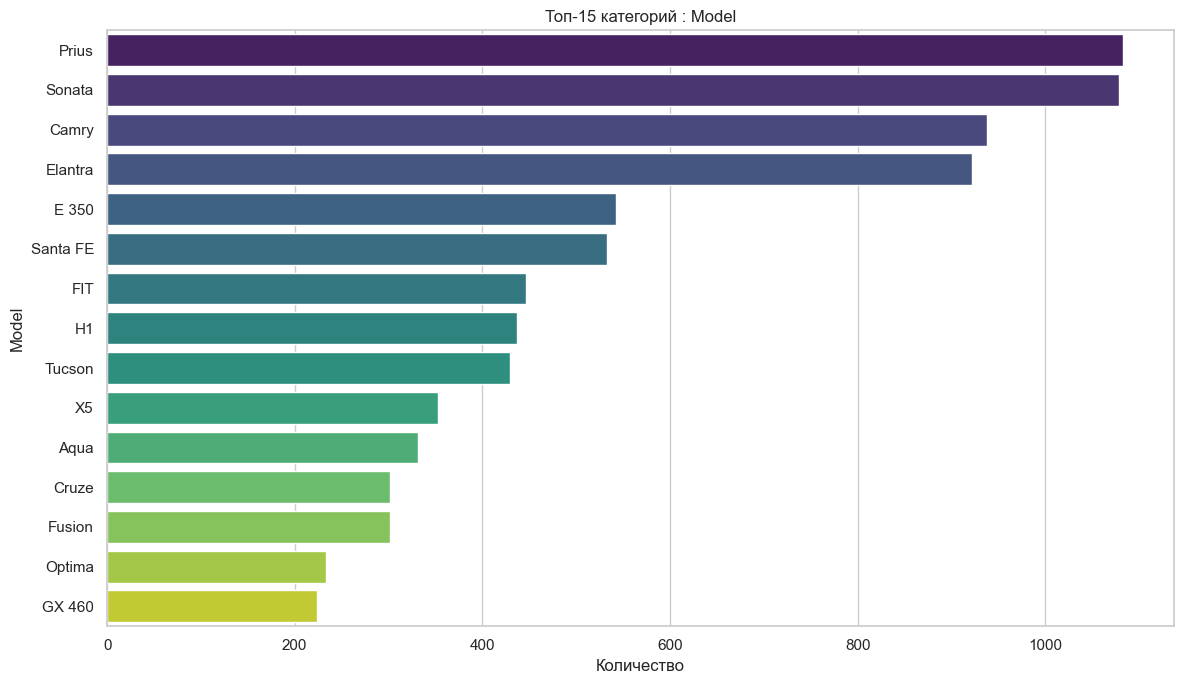

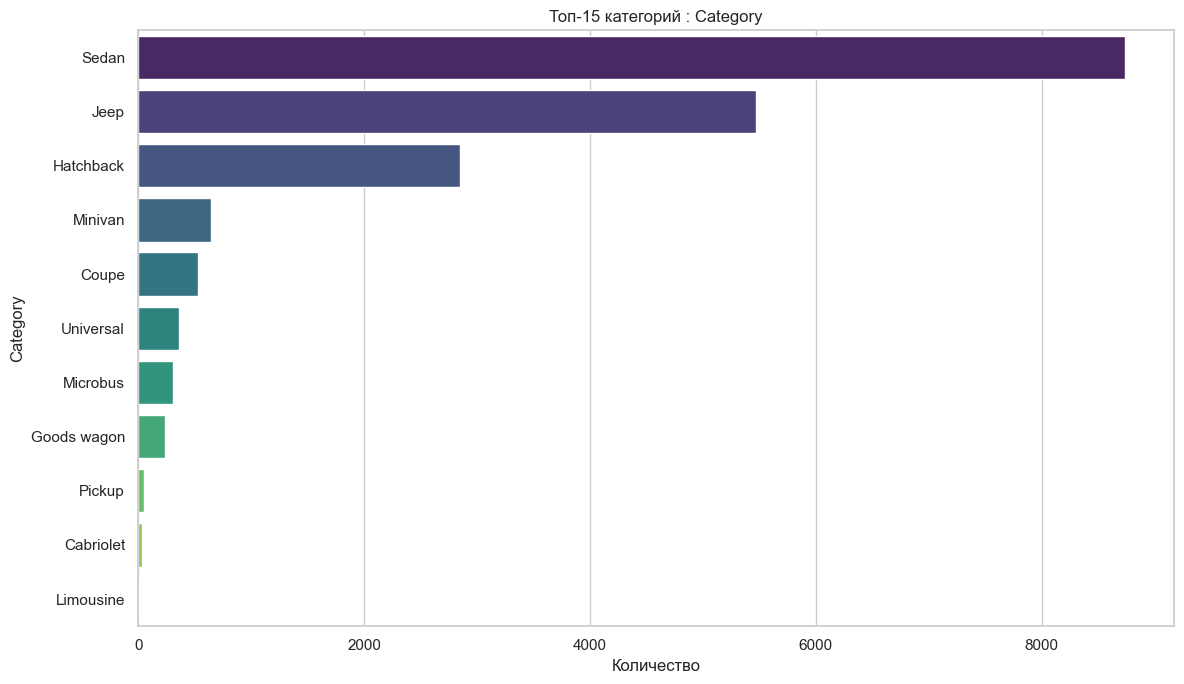

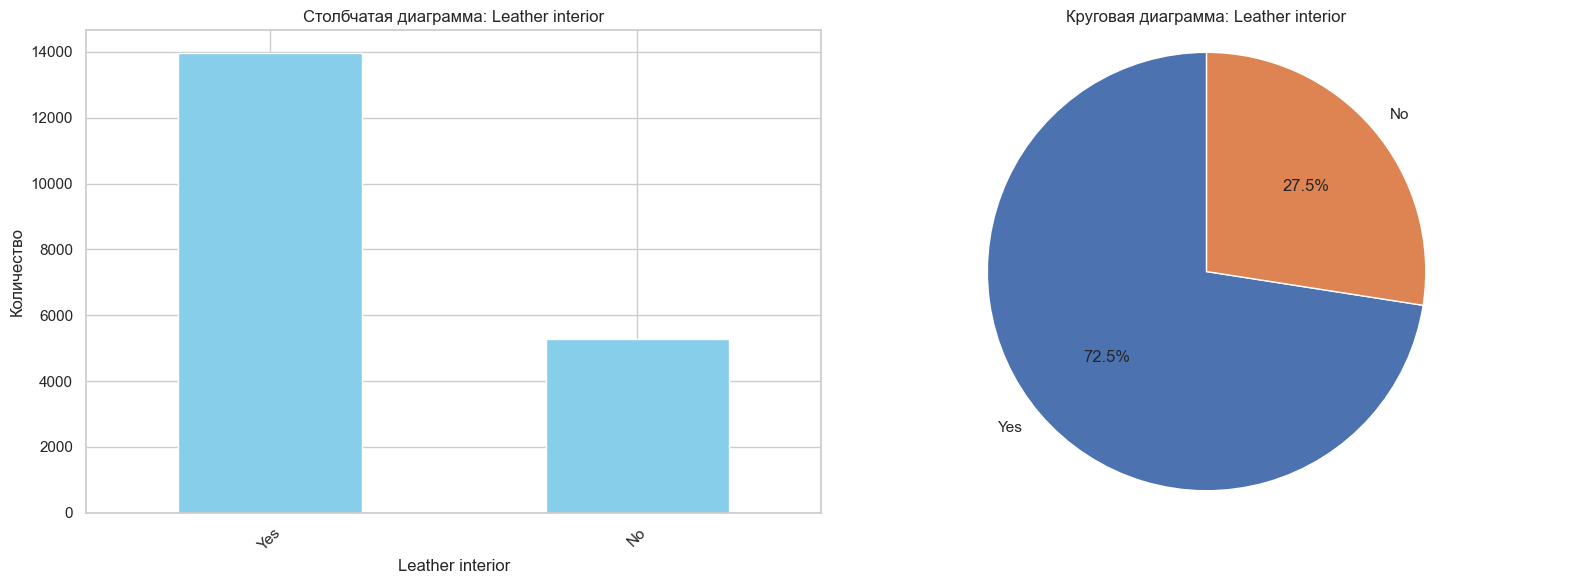

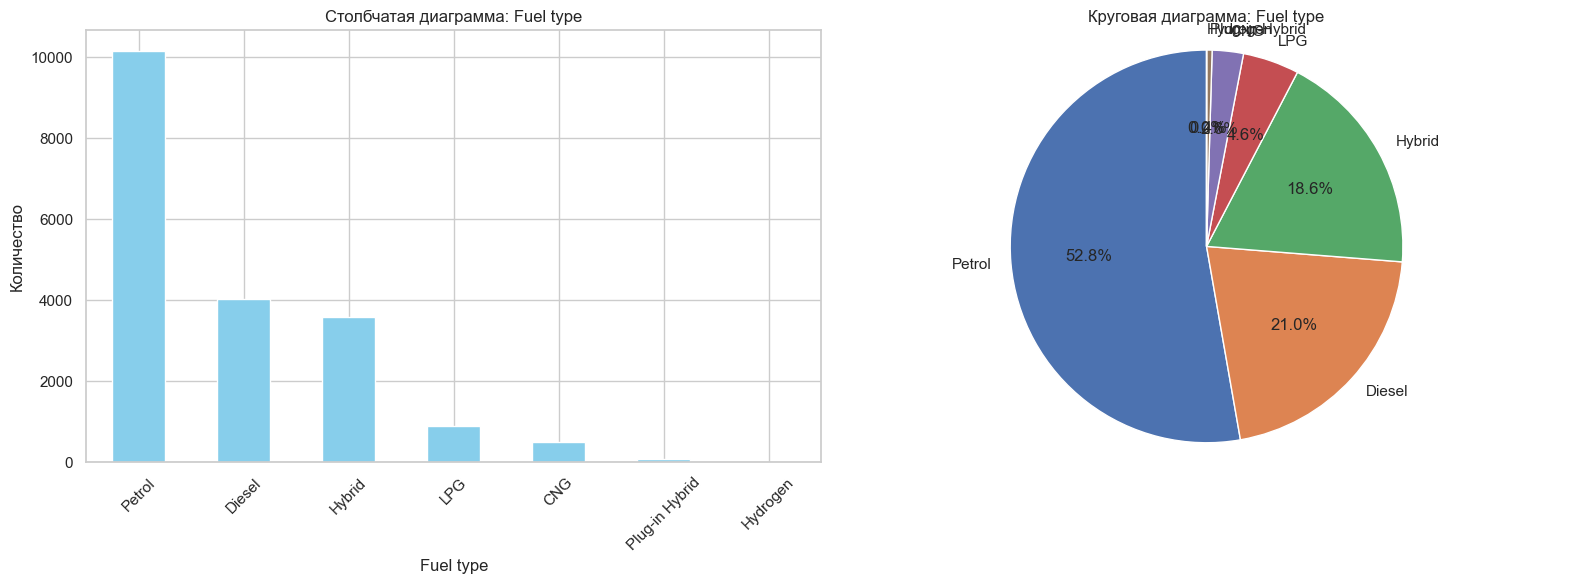

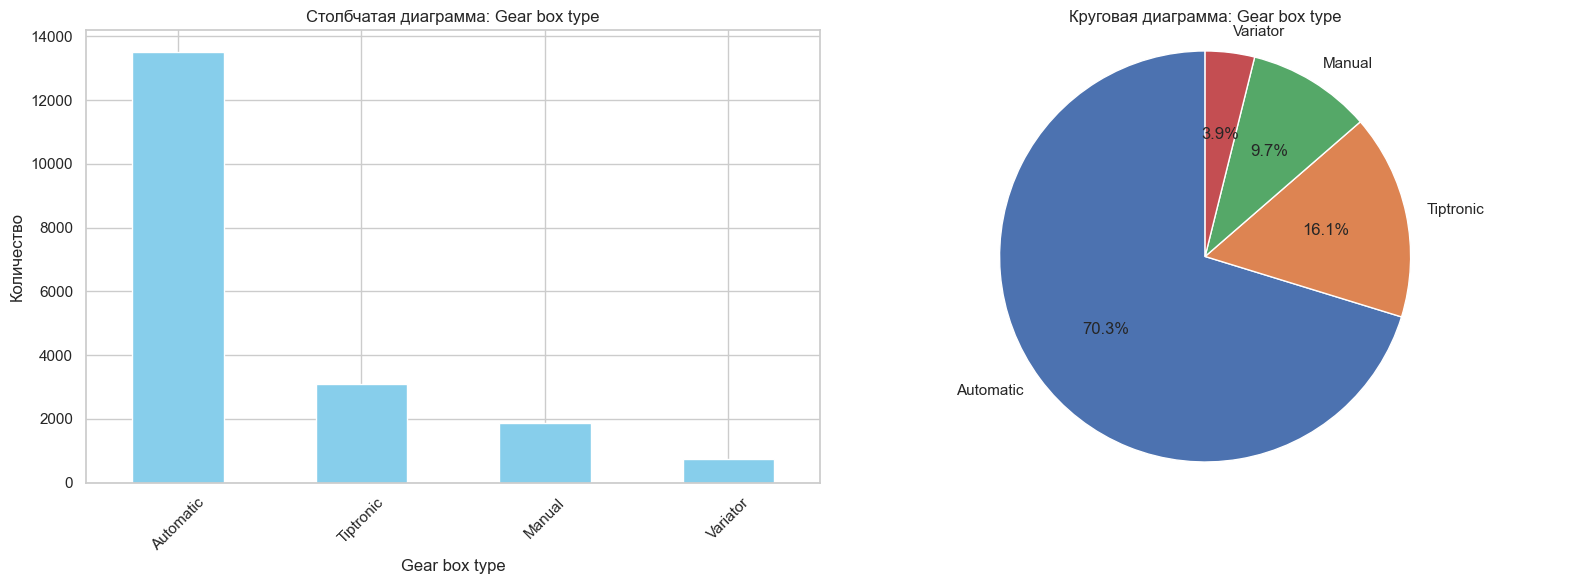

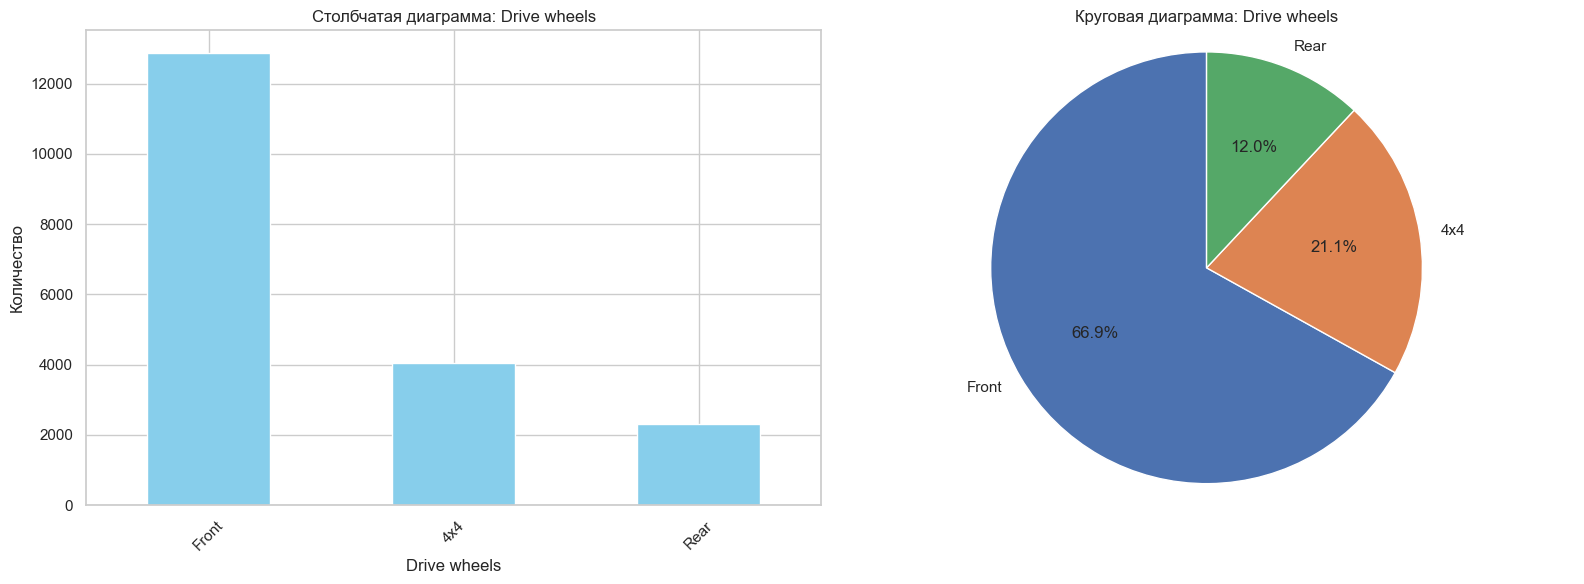

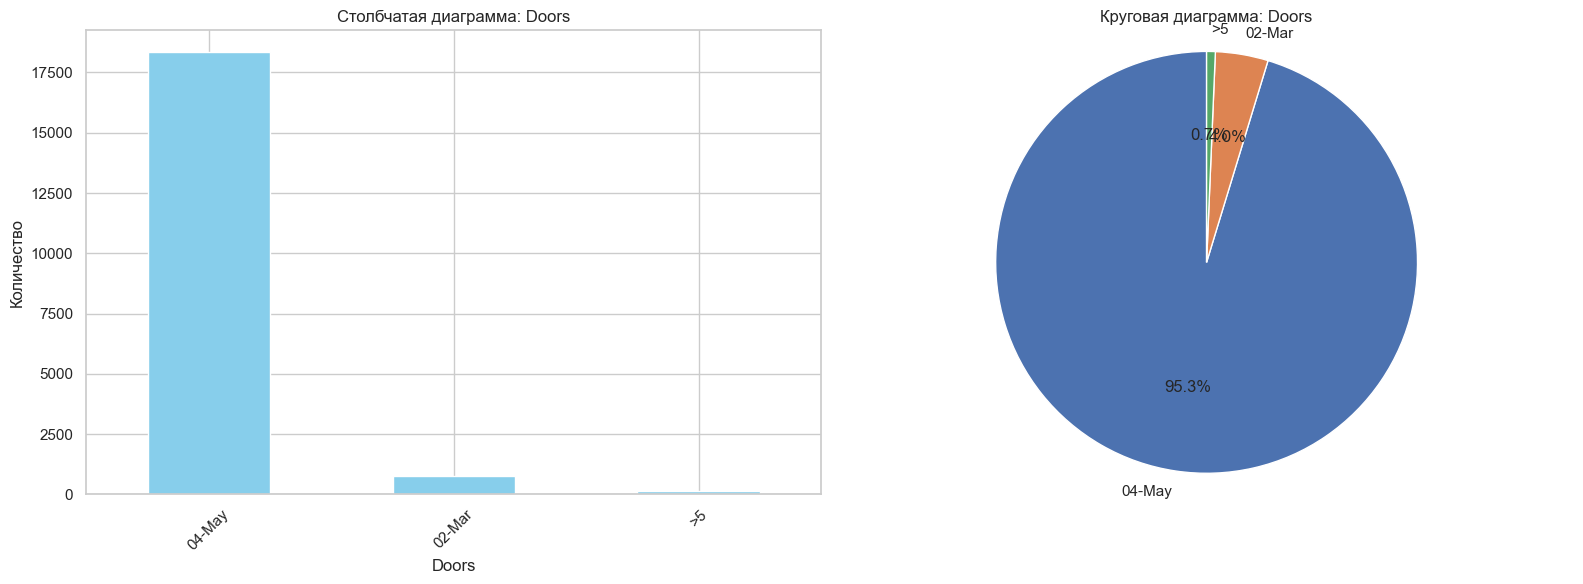

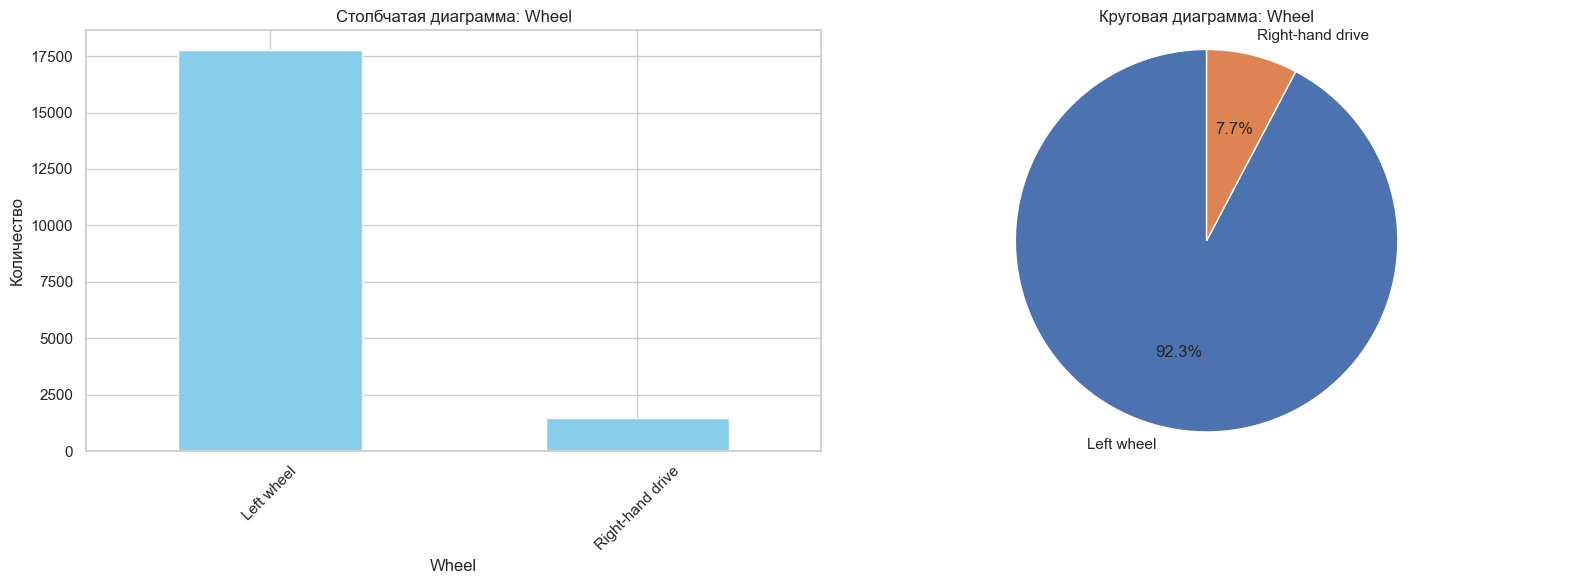

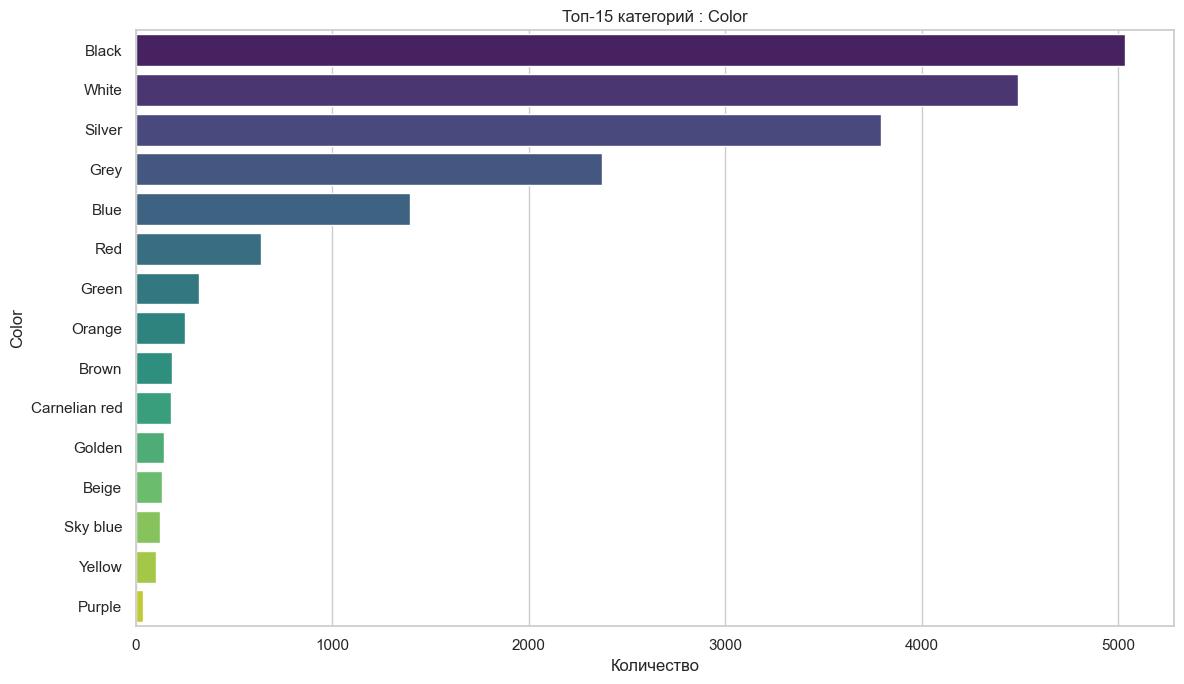

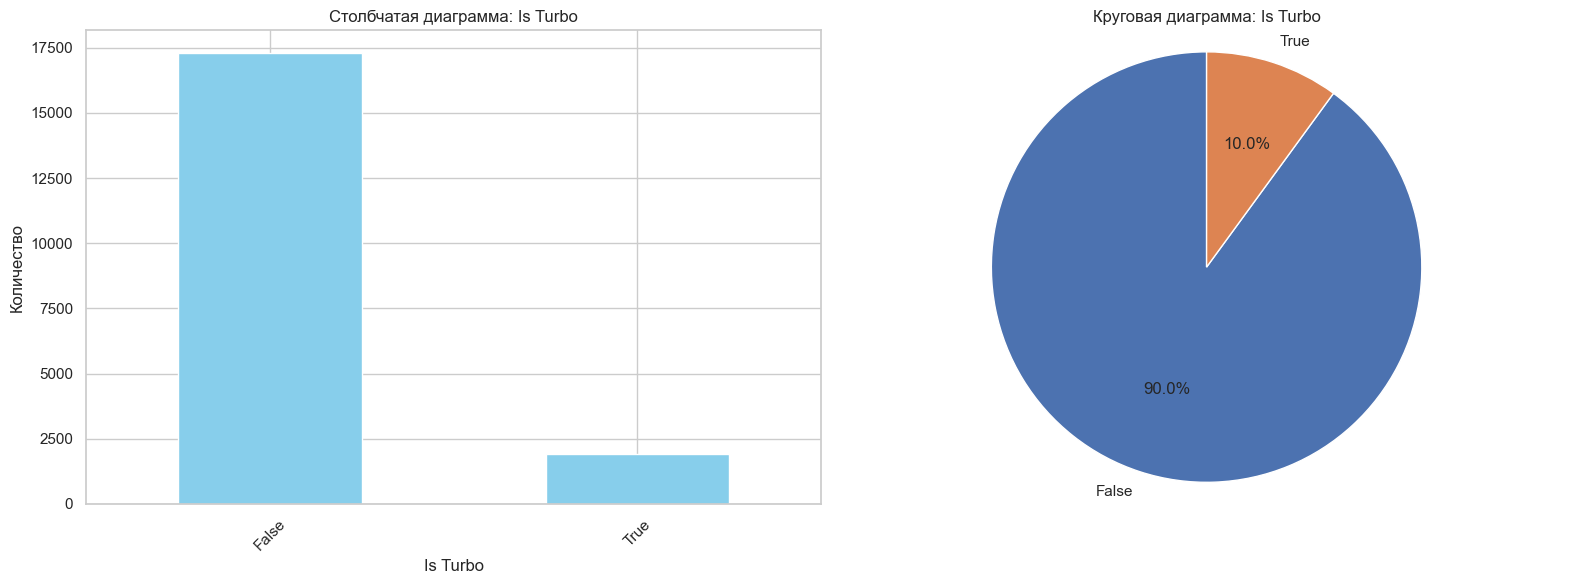

In [582]:
for feature in categorical_columns:
    value_counts = df[feature].value_counts()

    if len(value_counts) <= 10:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

        value_counts.plot(kind='bar', ax=ax1, color='skyblue')
        ax1.set_title(f'Столбчатая диаграмма: {feature}')
        ax1.set_ylabel('Количество')
        ax1.set_xlabel(feature)
        ax1.tick_params(axis='x', rotation=45)

        ax2.pie(value_counts.values, labels=value_counts.index, autopct='%1.1f%%', startangle=90)
        ax2.set_title(f'Круговая диаграмма: {feature}')
        ax2.axis('equal')

    else:
        plt.figure(figsize=(12, 7))
        top_n = value_counts.head(15)

        sns.barplot(x=top_n.values, y=top_n.index, hue=top_n.index, legend=False, palette='viridis')
        plt.title(f'Топ-15 категорий : {feature}')
        plt.xlabel('Количество')
        plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

In [583]:
numeric_columns = ['Price', 'Prod. year', 'Cylinders', 'Airbags', 'Levy', 'Mileage', 'Engine volume']

In [584]:
df['Levy'] = pd.to_numeric(df['Levy'], errors='coerce')

In [585]:
print(df['Levy'].isnull().sum())

5819


In [586]:
df['Price'].corr(df['Levy'])

np.float64(0.06329135669020561)

Можно заполнить медианой по группам (например, по "Engine volume", "Manufacturer", "Category") или общей медианой/модой, если групповой подход не полностью устраняет пропуски.

In [587]:
df.Levy = (
    df.groupby(["Engine volume" ,"Manufacturer", "Category"])["Levy"]
             .transform(lambda x: x.fillna(x.median()))
)

/Users/maryc/PycharmProjects/PythonProject/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/maryc/PycharmProjects/PythonProject/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/maryc/PycharmProjects/PythonProject/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/maryc/PycharmProjects/PythonProject/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/maryc/PycharmProjects/PythonProject/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.

In [588]:
df['Price'].corr(df['Levy'])

np.float64(0.009626388934627219)

In [589]:
df.isnull().sum()

Price                  0
Levy                1436
Manufacturer           0
Model                  0
Prod. year             0
Category               0
Leather interior       0
Fuel type              0
Engine volume          0
Mileage                0
Cylinders              0
Gear box type          0
Drive wheels           0
Doors                  0
Wheel                  0
Color                  0
Airbags                0
Is Turbo               0
dtype: int64

In [590]:
glob_median = df["Levy"].median()
df["Levy"] = df["Levy"].fillna(glob_median)

In [591]:
df[df['Mileage'] > 1000000]

,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags,Is Turbo
144,4300,800.0,MERCEDES-BENZ,208,1985,Universal,No,Diesel,2.5,1111111,4.0,Manual,Rear,04-May,Left wheel,Black,1,False
493,15994,777.0,TOYOTA,Camry,2014,Sedan,No,Petrol,2.5,1440000,4.0,Automatic,Front,04-May,Left wheel,Silver,0,False
985,2700,1363.0,OPEL,Vectra,1997,Sedan,No,CNG,1.6,777777777,4.0,Automatic,Front,04-May,Left wheel,Beige,2,False
1146,13485,3993.0,BMW,525,2003,Sedan,Yes,Petrol,2.5,7777787,6.0,Manual,Rear,04-May,Left wheel,Silver,10,False
1404,9095,1036.0,BMW,328,2002,Sedan,No,Petrol,2.8,55556665,6.0,Manual,Rear,04-May,Left wheel,Silver,6,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18673,40,1368.0,HONDA,FIT,2007,Hatchback,Yes,Petrol,1.6,15000000,7.0,Automatic,Front,04-May,Left wheel,Sky blue,9,False
18846,14113,503.0,TOYOTA,Prius,2005,Hatchback,Yes,Hybrid,1.5,2696320,4.0,Automatic,Front,04-May,Left wheel,Grey,6,False
18950,3607,642.0,VOLKSWAGEN,Jetta,1999,Sedan,No,CNG,2.0,3000000,4.0,Manual,Front,04-May,Left wheel,Black,2,False
19167,18817,1995.0,FORD,Transit,2003,Microbus,No,Diesel,2.4,2147483647,4.0,Manual,Front,02-Mar,Left wheel,White,2,True


In [592]:
df = df[df['Mileage'] <= 1000000]

Выбросы Mileage > 1000000 были удалены. Это экстремально высокие значения, которые, вероятно, являются ошибками ввода данных или представляют собой очень редкие исключения, способные сильно исказить модель.

In [593]:
df['Doors'] = df['Doors'].replace({'04-May': '4-5', '02-Mar': '2-3'})

/var/folders/8_/ss2c3myd785fm4m9w3q294100000gn/T/ipykernel_15406/370691956.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Doors'] = df['Doors'].replace({'04-May': '4-5', '02-Mar': '2-3'})


In [594]:
df['Doors'].value_counts()

Doors
4-5    18267
2-3      771
>5       125
Name: count, dtype: int64

In [595]:
df = df[(df['Price'] > 500) & (df['Price'] <= 25000000)]

In [596]:
df.shape

(17501, 18)

Выбросы Price < 500 и Price > 25000000 были удалены. Эти границы выбраны для удаления явных нереалистичных значений.

In [597]:
df[df.Levy > 5000]

,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags,Is Turbo
61,10349,5672.5,TOYOTA,VOXY,2007,Minivan,Yes,Petrol,2.4,170000,4.0,Automatic,Front,4-5,Right-hand drive,Black,6,False
115,11917,11714.0,MERCEDES-BENZ,E 500 AMG,2003,Sedan,Yes,Petrol,5.0,150000,12.0,Tiptronic,Rear,4-5,Right-hand drive,White,12,False
282,21326,11710.0,MERCEDES-BENZ,CLS 500,2006,Sedan,Yes,Petrol,5.0,2000,8.0,Automatic,Rear,4-5,Left wheel,Grey,12,False
470,15000,7058.0,SUBARU,Legacy,2008,Sedan,No,Petrol,3.0,138000,6.0,Tiptronic,4x4,4-5,Left wheel,Black,8,False
511,10976,11710.0,MERCEDES-BENZ,S 500 long,1997,Sedan,Yes,Petrol,5.0,167000,8.0,Automatic,Rear,4-5,Left wheel,Black,8,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17767,10349,5681.0,MITSUBISHI,Pajero,1996,Jeep,No,Petrol,2.4,169800,4.0,Automatic,4x4,2-3,Right-hand drive,Red,2,False
17777,10036,5603.0,HYUNDAI,Sonata,2014,Sedan,Yes,LPG,20.0,333686,4.0,Automatic,Front,4-5,Left wheel,Silver,4,False
18957,14740,11706.0,MERCEDES-BENZ,E 500 AVG,2005,Sedan,Yes,Petrol,5.0,56000,12.0,Tiptronic,Rear,4-5,Right-hand drive,Black,12,False
18984,11917,11714.0,MERCEDES-BENZ,E 500,2003,Sedan,Yes,Petrol,5.0,150000,12.0,Tiptronic,Rear,4-5,Right-hand drive,White,12,False


In [598]:
df[df['Engine volume'] == 0]

,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags,Is Turbo
2010,53941,87.0,TESLA,Model X,2018,Sedan,Yes,Petrol,0.0,81907,6.0,Automatic,4x4,4-5,Left wheel,Silver,12,False
3105,2430,87.0,MERCEDES-BENZ,C 250,2013,Coupe,Yes,Petrol,0.0,121600,4.0,Automatic,Rear,4-5,Left wheel,White,12,False
3516,27356,87.0,HYUNDAI,Elantra,2016,Sedan,Yes,LPG,0.0,65004,4.0,Automatic,Front,4-5,Left wheel,White,4,False
4814,17663,87.0,TOYOTA,Aqua,2012,Hatchback,Yes,Petrol,0.0,118000,4.0,Automatic,Front,4-5,Left wheel,Grey,4,False
7022,17663,87.0,TOYOTA,Aqua,2012,Hatchback,Yes,Petrol,0.0,118000,4.0,Automatic,Front,4-5,Left wheel,Grey,4,False
7685,47076,87.0,SSANGYONG,REXTON,2016,Jeep,Yes,Diesel,0.0,73968,4.0,Automatic,Front,4-5,Left wheel,Black,4,False
10603,12231,87.0,TOYOTA,Prius,2010,Hatchback,No,Hybrid,0.0,0,4.0,Automatic,Front,4-5,Left wheel,Golden,0,False


In [599]:
df = df[df['Engine volume'] != 0]

In [600]:
df.reset_index(inplace=True, drop=True)

### 4 дупликаты

In [601]:
df.duplicated().sum()

np.int64(2771)

In [602]:
df = df.drop_duplicates()

In [603]:
df.reset_index(inplace=True)

In [604]:
df.duplicated().sum()

np.int64(0)

df.drop_duplicates() - Полные дубликаты строк были удалены

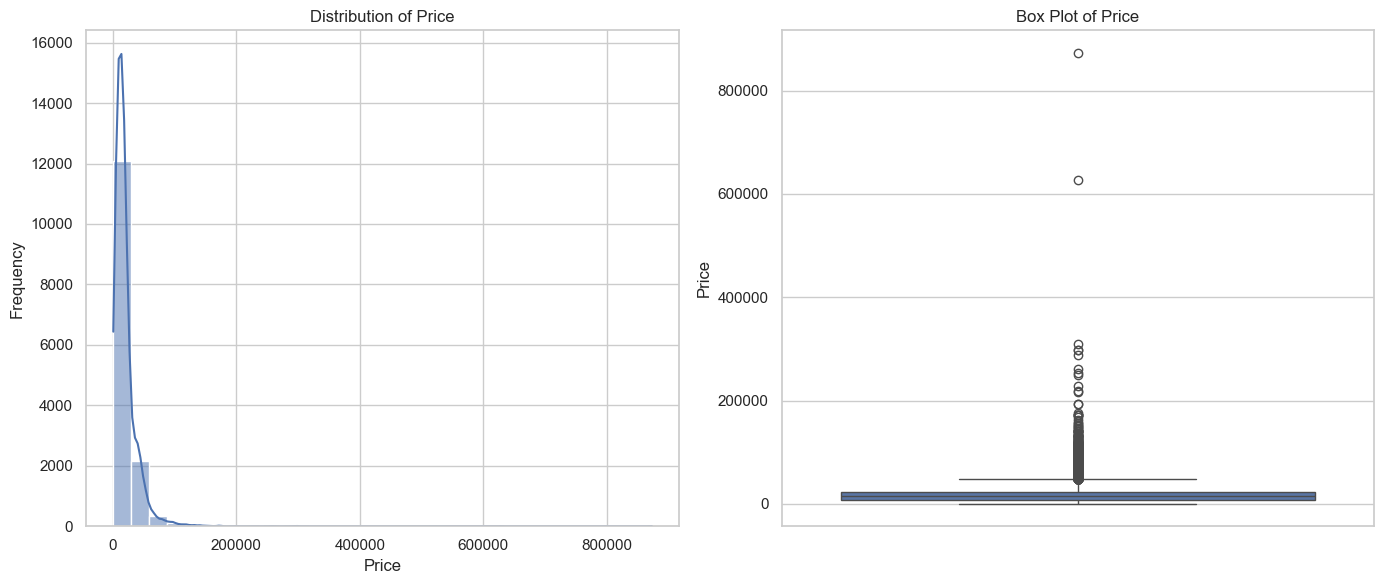

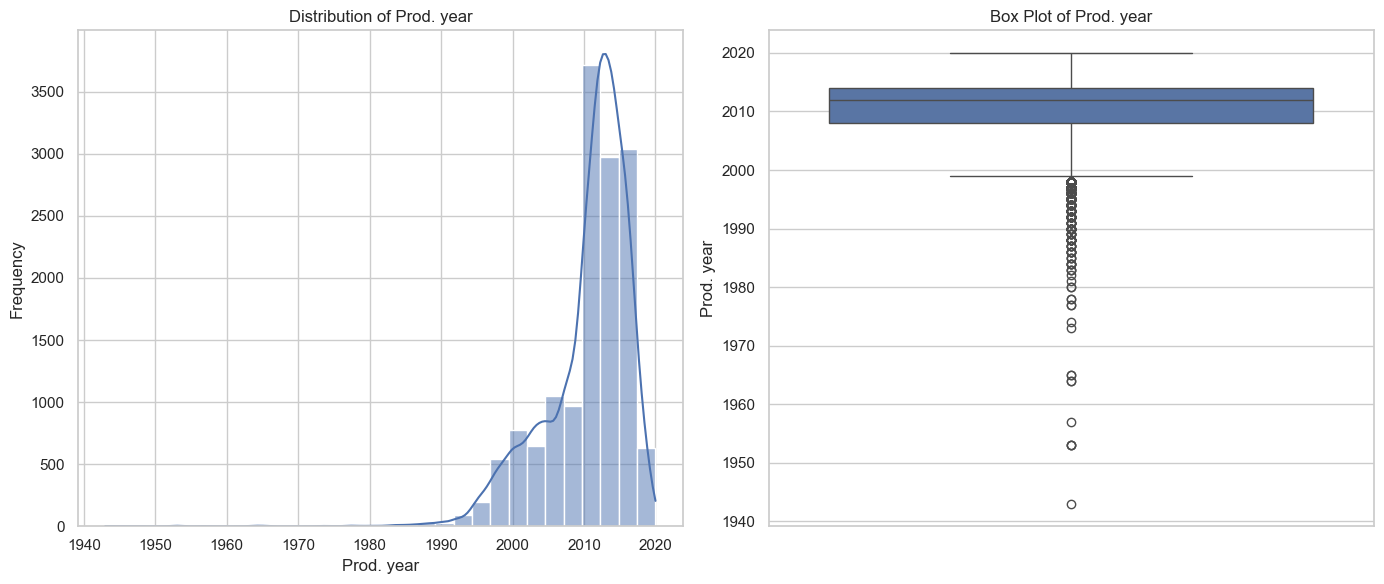

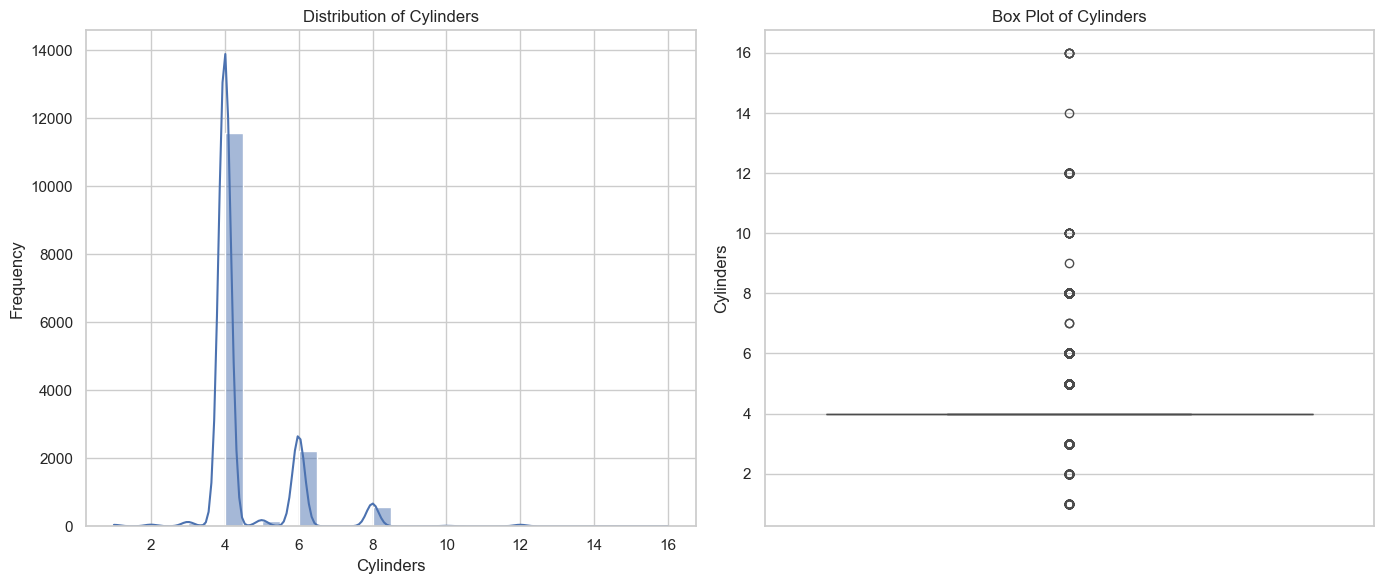

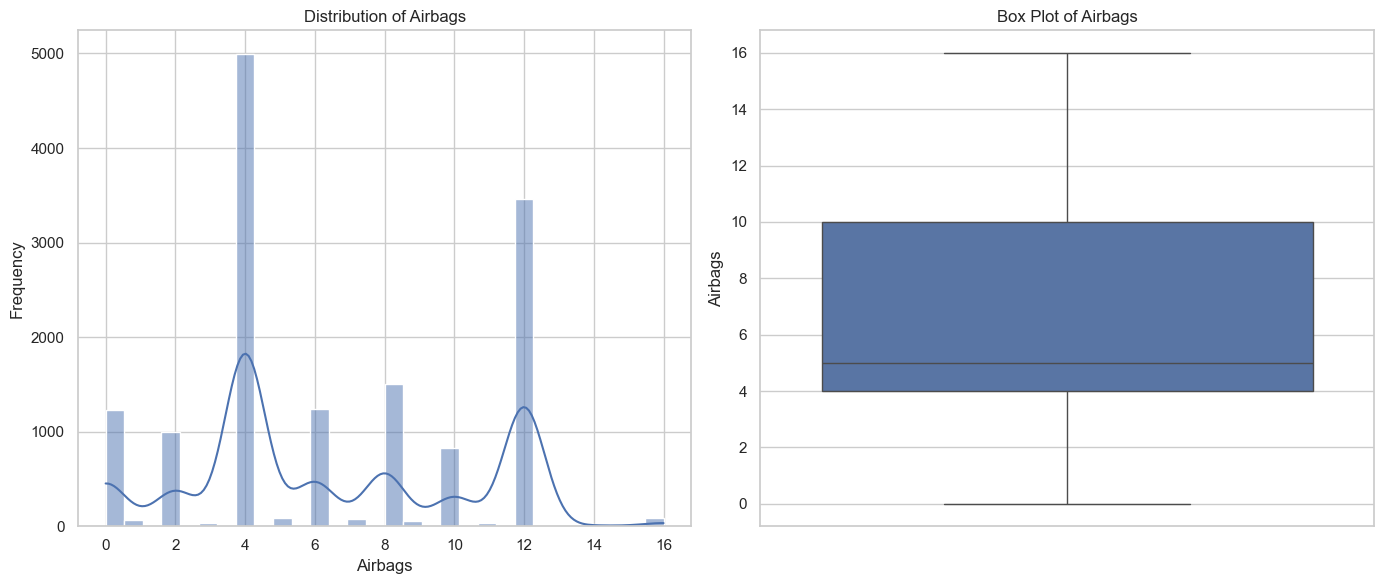

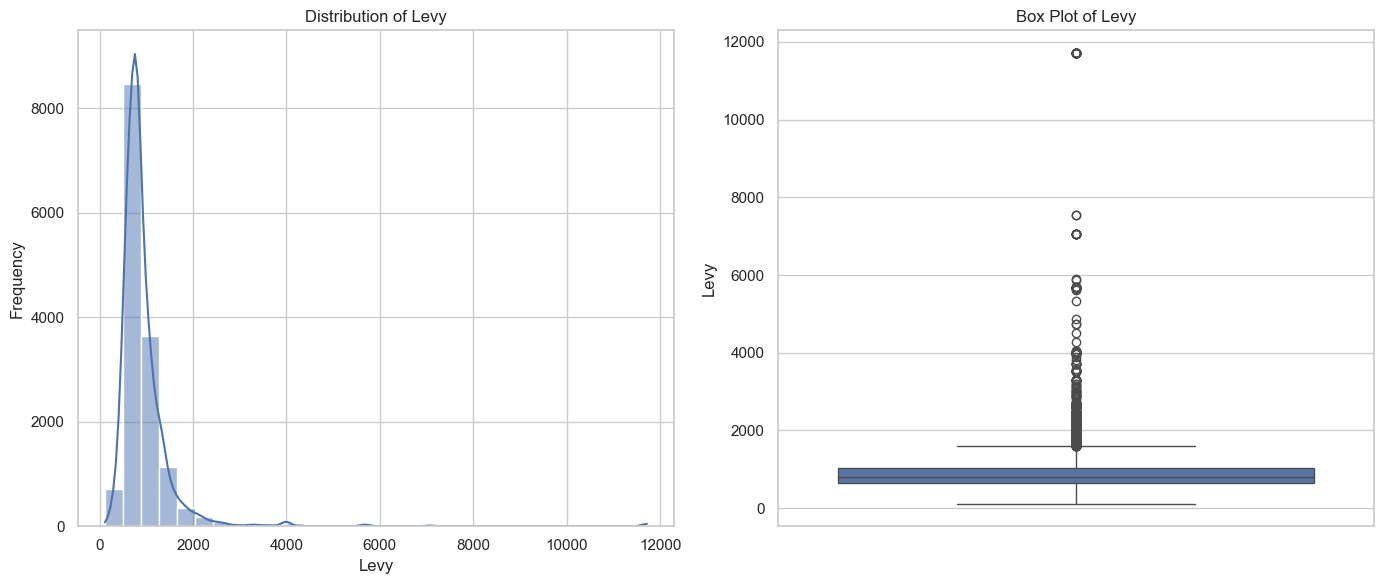

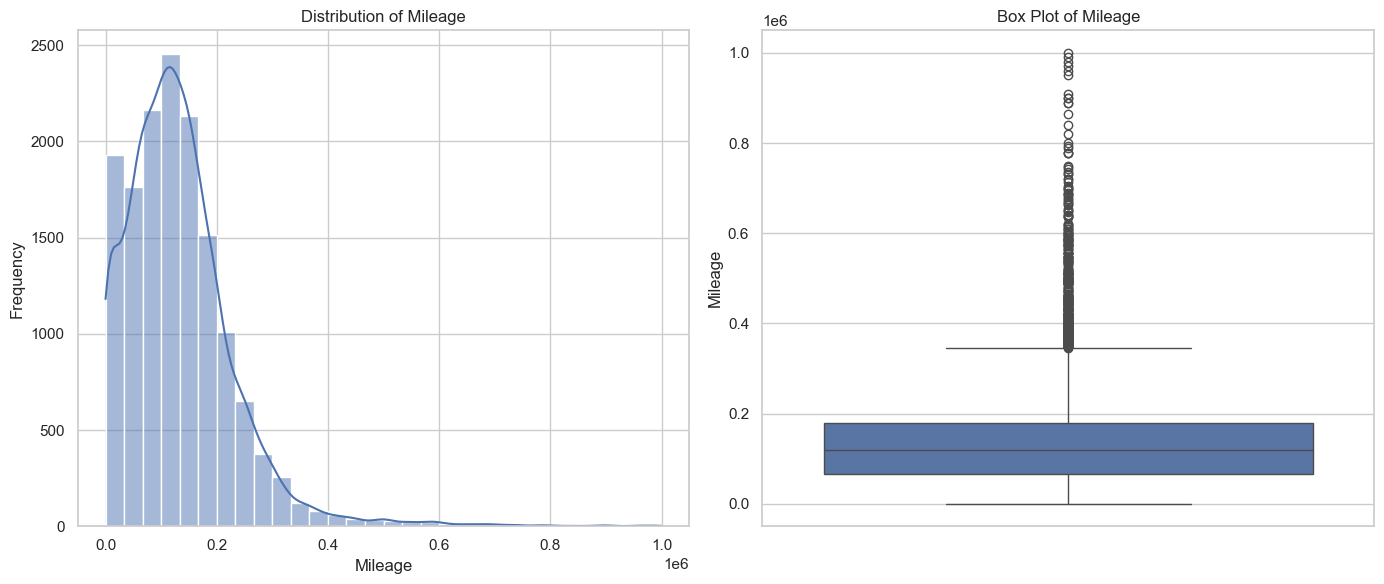

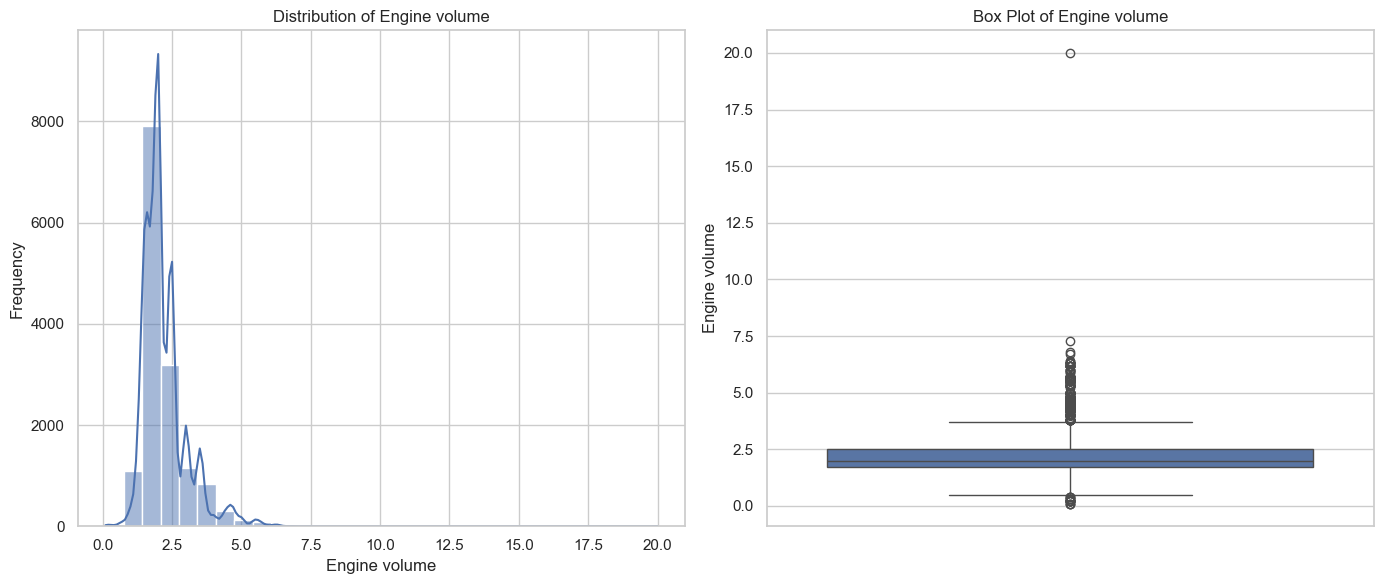

In [605]:
for feature in numeric_columns:
    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    sns.histplot(df[feature].dropna(), kde=True, bins=30)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')

    plt.subplot(1, 2, 2)
    sns.boxplot(y=df[feature].dropna())
    plt.title(f'Box Plot of {feature}')
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

### 5 Предположите наличие зависимостей в признаках.

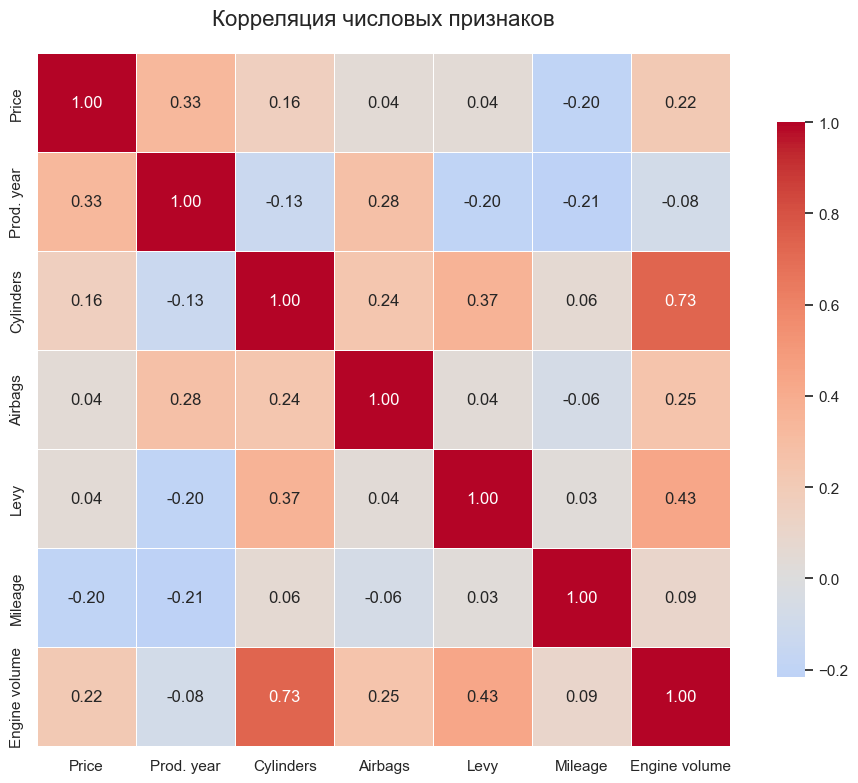

In [606]:
plt.figure(figsize=(10, 8))
correlation_matrix = df[numeric_columns].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.2f', linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Корреляция числовых признаков', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

### 6 кодирование

In [607]:
df.dropna()

,index,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags,Is Turbo
0,0,13328,1399.0,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005,6.0,Automatic,4x4,4-5,Left wheel,Silver,12,False
1,1,16621,1018.0,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3.0,192000,6.0,Tiptronic,4x4,4-5,Left wheel,Black,8,False
2,2,8467,574.0,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000,4.0,Variator,Front,4-5,Right-hand drive,Black,2,False
3,3,3607,862.0,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966,4.0,Automatic,4x4,4-5,Left wheel,White,0,False
4,4,11726,446.0,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901,4.0,Automatic,Front,4-5,Left wheel,Silver,4,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14718,17485,8781,1107.0,OPEL,Combo,2007,Goods wagon,No,Diesel,1.7,236000,4.0,Manual,Front,4-5,Left wheel,Beige,4,True
14719,17486,7840,2476.0,NISSAN,Skyline,2003,Sedan,Yes,Petrol,3.0,220000,6.0,Tiptronic,Rear,4-5,Right-hand drive,White,0,False
14720,17490,8467,891.0,MERCEDES-BENZ,CLK 200,1999,Coupe,Yes,CNG,2.0,300000,4.0,Manual,Rear,2-3,Left wheel,Silver,5,True
14721,17491,15681,831.0,HYUNDAI,Sonata,2011,Sedan,Yes,Petrol,2.4,161600,4.0,Tiptronic,Front,4-5,Left wheel,Red,8,False


In [608]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [609]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, shuffle=True)

Данные разделены на обучающую и тестовую выборки

In [610]:
num_cols = X_train.select_dtypes(include=["number"]).columns
cat_cols = X_train.select_dtypes(exclude=["number"]).columns

Автоматическое определение числовых (num_cols) и категориальных (cat_cols) признаков.

**StandardScaler**

In [611]:
numeric_pipe_stand = Pipeline(steps=[
    ("scaler", StandardScaler())
])

**MinMaxScaler**

In [612]:
numeric_pipe_mm = Pipeline(steps=[
    ("scaler", MinMaxScaler())
])

Категориальные признаки

In [613]:
categorical_pipe = Pipeline(steps=[
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

In [614]:
preprocessor_stand = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe_stand, num_cols),
        ("cat", categorical_pipe, cat_cols),
    ],
    sparse_threshold=0.0
)

In [615]:
preprocessor_mm = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe_mm, num_cols),
        ("cat", categorical_pipe, cat_cols),
    ],
    sparse_threshold=0.0
)

### 7 pca

#### minmax

In [616]:
pipe = Pipeline(steps=[
    ("prep", preprocessor_mm),
    ("pca", PCA(n_components=0.95, svd_solver="full"))
])

Метод главных компонент применен для уменьшения размерности, сохраняя 95% объясненной дисперсии     
svd_solver="full" используется для небольших и средних наборов данных

In [617]:
Z_train = pipe.fit_transform(X_train)
Z_test  = pipe.transform(X_test)

Обучение пайплайна и преобразование тренировочных данных
Преобразование тестовых данных

In [618]:
Z_train_df = pd.DataFrame(Z_train, columns=[f"PC{i+1}" for i in range(Z_train.shape[1])])
Z_train_df["price_log"] = y_train.values

Создание DataFrame из главных компонент 
 Добавление целевой переменной

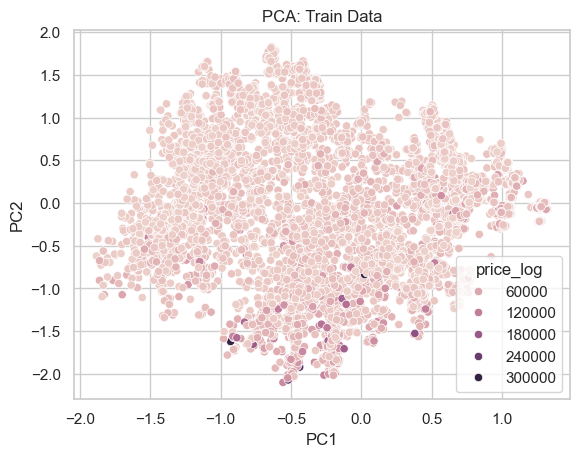

In [619]:
sns.scatterplot(data=Z_train_df, x="PC1", y="PC2", hue="price_log")
plt.title("PCA: Train Data")
plt.show()

In [620]:
X_pre = preprocessor_mm.fit_transform(X_train)

Применяет препроцессор к тренировочным данным

In [621]:
pca_full = PCA().fit(X_pre)

Создает PCA объект и обучает на полных данных 

In [622]:
evr = pca_full.explained_variance_ratio_

Вычисляет долю объясненной дисперсии для каждой компоненты

In [623]:
cum_evr = np.cumsum(evr)

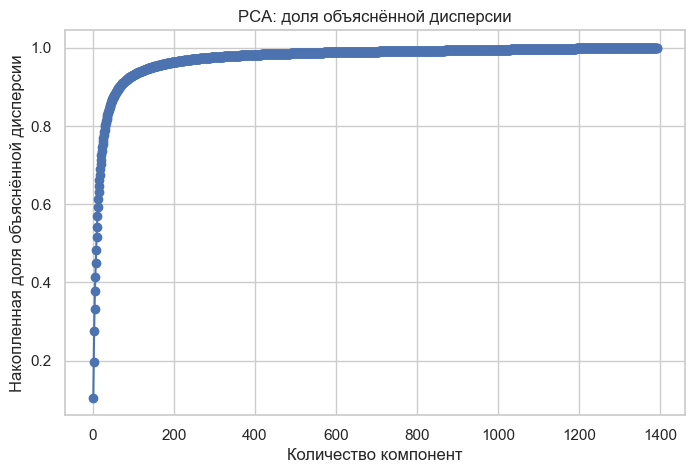

In [624]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_evr) + 1), cum_evr, marker="o")
plt.xlabel("Количество компонент")
plt.ylabel("Накопленная доля объяснённой дисперсии")
plt.title("PCA: доля объяснённой дисперсии")
plt.grid(True)
plt.show()

In [625]:
for t in [0.9, 0.95, 0.99]:
    n_comp = np.argmax(cum_evr >= t) + 1
    print(f"{t*100:.0f}% дисперсии объясняют {n_comp} компонент")

90% дисперсии объясняют 66 компонент
95% дисперсии объясняют 145 компонент
99% дисперсии объясняют 680 компонент


#### standart

In [626]:
pipe = Pipeline(steps=[
    ("prep", preprocessor_mm),
    ("pca", PCA(n_components=0.95, svd_solver="auto")) 
])

In [627]:
Z_train = pipe.fit_transform(X_train)
Z_test  = pipe.transform(X_test)

In [628]:
Z_train_df = pd.DataFrame(Z_train, columns=[f"PC{i+1}" for i in range(Z_train.shape[1])])
Z_train_df["price_log"] = y_train.values

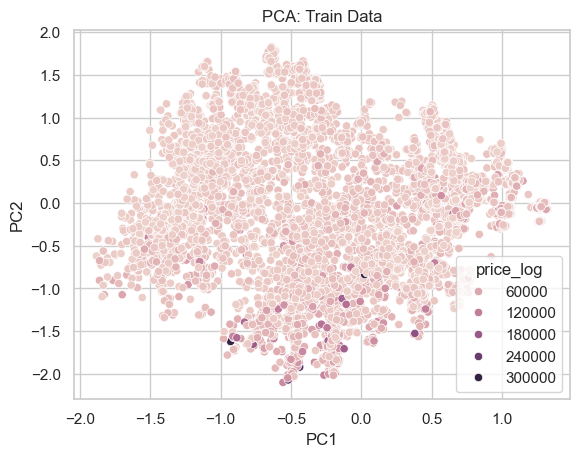

In [629]:
sns.scatterplot(data=Z_train_df, x="PC1", y="PC2", hue="price_log")
plt.title("PCA: Train Data")
plt.show()

In [630]:
X_pre = preprocessor_stand.fit_transform(X_train)

In [631]:
pca_full = PCA().fit(X_pre)

In [632]:
evr = pca_full.explained_variance_ratio_

In [633]:
cum_evr = np.cumsum(evr)

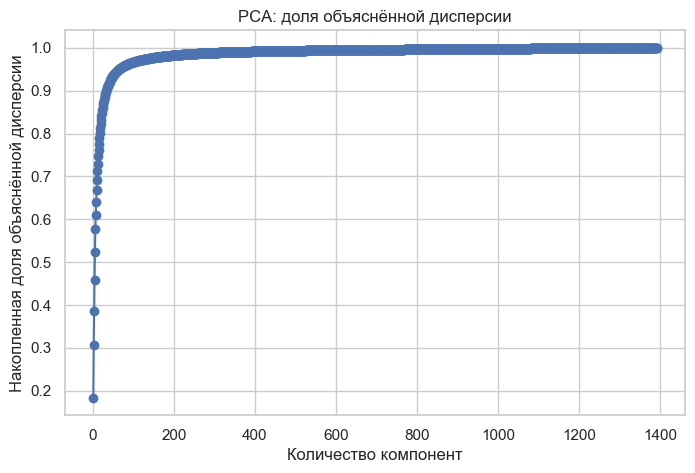

In [634]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_evr) + 1), cum_evr, marker="o")
plt.xlabel("Количество компонент")
plt.ylabel("Накопленная доля объяснённой дисперсии")
plt.title("PCA: доля объяснённой дисперсии")
plt.grid(True)
plt.show()

In [635]:
for t in [0.9, 0.95, 0.99]:
    n_comp = np.argmax(cum_evr >= t) + 1
    print(f"{t*100:.0f}% дисперсии объясняют {n_comp} компонент")

90% дисперсии объясняют 34 компонент
95% дисперсии объясняют 65 компонент
99% дисперсии объясняют 343 компонент
